## Task 1



<div dir="rtl">

### فهم المشكلة

**1. ايش السؤال الي تبينه العيادة؟**

العيادة تبي تعرف إذا كانت المريضة معرضة للإصابة بمرض السكري أو لا بناء على بياناتها الصحية زي مستوى السكر، العمر، ومؤشر كتلة الجسم وغيرها، ونعرف أي الأعمدة (مثل `Glucose` و `BMI`) أكثر ارتباطًا بالسكري

**2. وش الـ Target؟**

العمود المستهدف (`Target`) هو `Outcome`، بحيث:

- 1 = مصابة بالسكري
- 0 = غير مصابة بالسكري

**3. مين الي بيستفيد من الإجابة وكيف؟**

الأطباء والعيادة هم أكثر ناس يستفيدون، بحيث تقدر العيادة تركز الفحص المبكر على الفئات الأكثر عرضة (مثلاً فئة عمرية أو `BMI` معين) بدل ما تفحص الكل، وهالشي يساعدهم يكشفون المرض بدري ويتخذون الإجراءات المناسبة لعلاج المرضى أو حمايتهم منه من بدري

</div>

 ### أول نظرة

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("diabetes.csv")

In [17]:
# حجم الداتا
print("Shape:")
print(df.shape)

# أنواع الأعمدة
print("\nData Types:")
print(df.dtypes)

# الإحصائيات الوصفية
print("\nStatistics:")
print(df.describe())

# القيم الناقصة
print("\nMissing Values:")
print(df.isnull().sum())

# عدد الصفوف المكررة
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# توزيع Outcome
print("\nOutcome Distribution:")
print(df["Outcome"].value_counts())

Shape:
(768, 9)

Data Types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Statistics:
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.

In [18]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print((df[cols] == 0).sum())

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


<div dir="rtl">

### أول نظرة على الداتا

- الداتا 768 صف و 9 أعمدة، ما فيها قيم ناقصة (`isnull`) ولا صفوف مكررة
- توزيع `Outcome`: 500 غير مصابة و 268 مصابة (نسبة المصابات 34.9%)

### تفكير وملاحظة عن البيانات

لاحظت أن صف الحد الأدنى (`min`) في هذي الأعمدة يساوي صفر:

- `Glucose`: 5 صفوف
- `BloodPressure`: 35 صف
- `SkinThickness`: 227 صف
- `Insulin`: 374 صف
- `BMI`: 11 صف

مع أن `isnull().sum()` أظهر إنه ما فيه قيم ناقصة، وجود أصفار في هذي الأعمدة مو منطقي طبيا، لأن مستحيل شخص حي يكون سكره أو ضغطه أو BMI عنده صفر. فالواضح إن هذي الأصفار بالغالب قيم ناقصة (Missing Values) انسجلت كأصفار بالغلط

(ملاحظة: وجود الإنسولين تقريبا نصه أصفار يعني إننا لو فكرنا نحذف كل هذي الصفوف راح نخسر نص الداتا تقريبا وهذا بياثر على تحليلنا، ولذلك بنترك قرار التعامل معها لخطوة التنظيف الجاية)

</div>

### EDA

<div dir="rtl">

### توقع قبل الرسم

أتوقع أن متوسط مستوى السكر (`Glucose`) عند المصابات بالسكري يكون أعلى من غير المصابات بحوالي 50 نقطة

قبل ما أرسم، قررت أحذف الـ 5 صفوف من أصل 768 اللي فيها قيمة صفر في عمود السكر (`Glucose`) (للرسم بس)، لأن السكر بـ صفر مو منطقي طبيا وبالغالب تمثل بيانات مفقودة مو قيمة حقيقية، ونخلي القرار النهائي للتنظيف بعدين

</div>

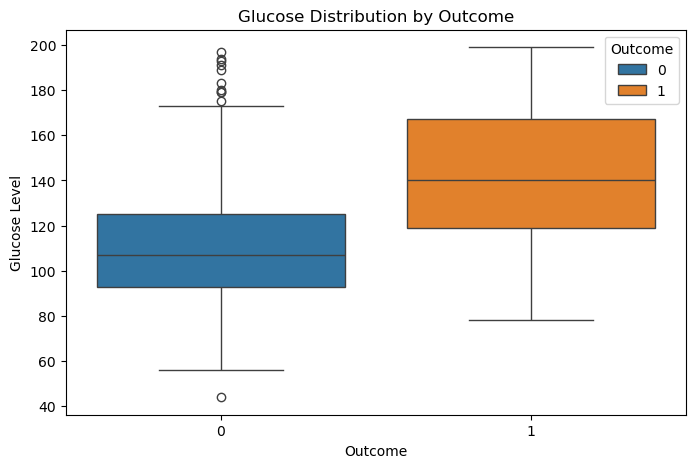

In [19]:
# حذف قيم السكر غير المنطقية
df_glucose = df[df["Glucose"] != 0]

plt.figure(figsize=(8,5))

sns.boxplot(
    data=df_glucose,
    x="Outcome",
    y="Glucose",
    hue="Outcome"
)

plt.title("Glucose Distribution by Outcome")
plt.xlabel("Outcome")
plt.ylabel("Glucose Level")
plt.legend(title="Outcome")

plt.show()

In [20]:
print(df_glucose.groupby("Outcome")["Glucose"].mean())

Outcome
0    110.643863
1    142.319549
Name: Glucose, dtype: float64


<div dir="rtl">

### ملاحظة بعد الرسم

متوسط مستوى السكر (`Glucose`) عند المصابات بالسكري بلغ 142.32، بينما بلغ 110.64 عند غير المصابات، بفارق 31.68 نقطة

توقعي غير صحيح لأني كنت متوقعة الفرق يكون حوالي 50 نقطة، بس النتائج بينت أن الفرق الفعلي يقارب 32 نقطة فقط. واتجاه التوقع كان صحيح، بحيث ثبت أن المصابات بالسكري عندهم متوسط سكر أعلى من غير المصابات بشكل واضح. زي ما يوضح الرسم أن الوسيط (`Median`) للمصابات يقارب 140 مقابل حوالي 107 عند غير المصابات

</div>

<div dir="rtl">

### توقع قبل الرسم

أتوقع ان عمود السكر (`Glucose`) يكون الاكثر ارتباط مع النتيجة (`Outcome`) بقيمة تقارب 0.55، لان مستوى السكر يعتبر من اهم المؤشرات المرتبطة بمرض السكري

وأتوقع ان مؤشر كتلة الجسم (`BMI`) يكون ثاني اكثر عمود ارتباط مع النتيجة بقيمة تقارب 0.30، لان زيادة الوزن تزيد من خطر الاصابة بالسكري

</div>

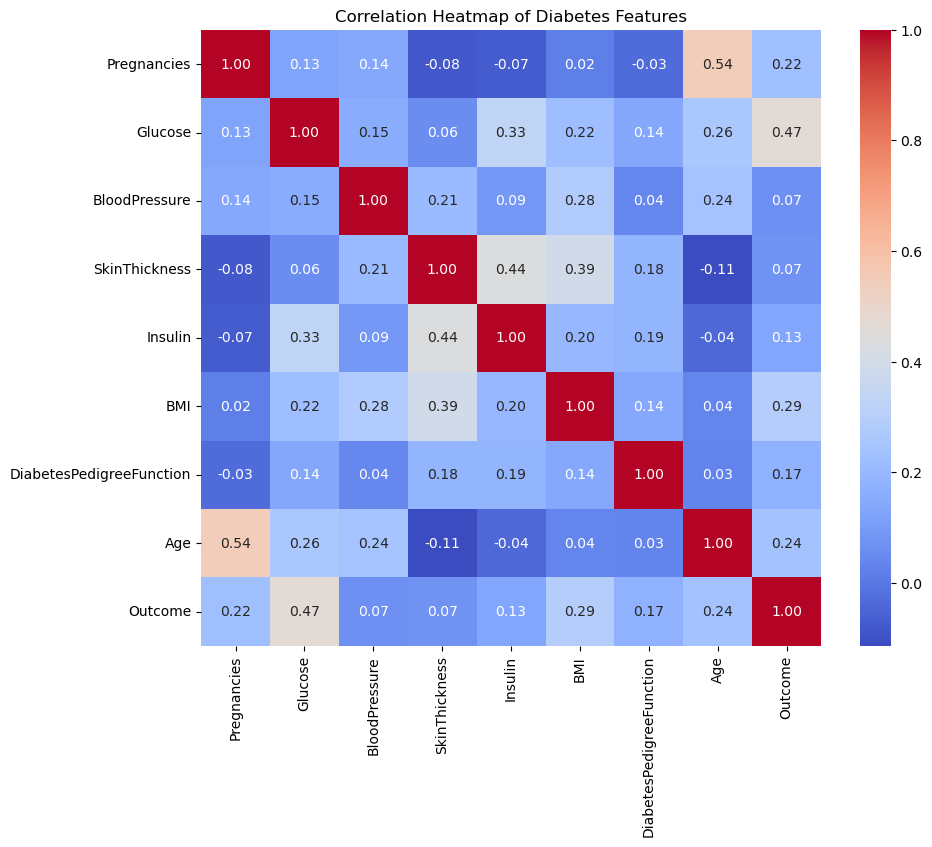

In [21]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap of Diabetes Features")
plt.show()

<div dir="rtl">

### ملاحظة بعد الرسم

توقعي كان غلط وما كان دقيق أعلى ارتباط مع النتيجة (`Outcome`) طلع لعمود السكر (`Glucose`) بقيمة 0.47 (لكن كنت متوقعة 0.55)، وبعده مؤشر كتلة الجسم (`BMI`) بقيمة 0.29

 ولاحظت ارتباط بين الأعمدة نفسها :
- العمر (`Age`) وعدد مرات الحمل (`Pregnancies`) بقيمة 0.54 (لان الحمل يزيد مع العمر)
- الإنسولين (`Insulin`) وسمك الجلد (`SkinThickness`) بقيمة 0.44 (ممكن يعطون معلومات متشابهة)

ومهم ننتبه إن هذي القيم ممكن تتغير شوي بعد التنظيف، لانها حاليا متأثرة بالأصفار الغير منطقية في السكر والإنسولين و`BMI`

</div>

<div dir="rtl">

## التنظيف و Decision Log

### المشكلة

اكتشفنا في الـ EDA أن الأعمدة `Glucose` و `BloodPressure` و `SkinThickness` و `Insulin` و `BMI` فيها أصفار غير منطقية طبيا، وهي بالغالب قيم ناقصة انسجلت كأصفار. أرقامها: `Glucose` 5 `BloodPressure` 35، `SkinThickness` 227، `Insulin` 374، `BMI` 11

</div>

In [22]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

rows_with_zero = (df[cols] == 0).any(axis=1).sum()

print("Rows with at least one zero:", rows_with_zero)
print("Percentage:", round(rows_with_zero / len(df) * 100, 1), "%")

Rows with at least one zero: 376
Percentage: 49.0 %


<div dir="rtl">

### Decision Log

| العمود | عدد الأصفار | القرار | القيمة المستخدمة | السبب |
| :--- | :---: | :--- | :---: | :--- |
| **Glucose** | 5 | حذف الصفوف | - | 5 من أصل 768 بس (0.7%)، نسبة صغيرة وما تأثر على حجم البيانات |
| **BMI** | 11 | حذف الصفوف | - | 11 من أصل 768 (1.4%) بس، فحذفها أفضل من تعبئتها بقيم تقديرية |
| **BloodPressure** | 35 | تعبئة بالوسيط | 72.0 | تمثل 4.6% من البيانات، ونسبتها كبيرة على الحذف، فنعوضها بالوسيط للحفاظ على عدد الصفوف |
| **SkinThickness** | 227 | تعبئة بالوسيط | 29.0 | حذف 227 صف معناه خسارة 29.6% من البيانات، وهذا يأثر على التحليل والنموذج |
| **Insulin** | 374 | تعبئة بالوسيط | 125.5 | يمثل 48.7% من البيانات، وحذفه معناه خسارة نص الداتا، لذلك الحذف غير مناسب |

**ملاحظة عن حساب الوسيط:**
- اخترنا **الوسيط** بدل المتوسط لأن البيانات فيها قيم شاذة عالية (مثلا في `Insulin` أقصى قيمة توصل 846 بينما أغلب القيم أقل بكثير، والقيم الشاذة تشد المتوسط وتخليه غير دقيق)
- حسبنا الوسيط **بعد استبعاد الأصفار** (بعد تحويلها لـ `NaN`)، لأن لو حسبناه مع الأصفار كان نزل الرقم وطلع غلط
- القيم الفعلية للوسيط: `Insulin = 125.5`، `SkinThickness = 29.0`، `BloodPressure = 72.0`

</div>

In [23]:
df_clean = df.copy()
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

# نحول الأصفار إلى NaN عشان تتعامل معها كقيم ناقصة
df_clean[cols] = df_clean[cols].replace(0, np.nan)

# حذف صفوف Glucose و BMI
before = len(df_clean)
df_clean = df_clean.dropna(subset=["Glucose", "BMI"])
print("Rows dropped:", before - len(df_clean))

# تعبئة الباقي بالوسيط (median يتجاهل NaN تلقائيا)
for col in ["BloodPressure", "SkinThickness", "Insulin"]:
    median = df_clean[col].median()
    print(col, "median:", median)
    df_clean[col] = df_clean[col].fillna(median)

print("Shape after cleaning:", df_clean.shape)
print(df_clean[cols].isnull().sum())
print((df_clean[cols] == 0).sum())

Rows dropped: 16
BloodPressure median: 72.0
SkinThickness median: 29.0
Insulin median: 125.5
Shape after cleaning: (752, 9)
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


<div dir="rtl">

### Feature Engineering

**Feature 1: Glucose_Category**
* **الحدود:**
  * `Normal`: أقل من 140
  * `Prediabetes`: من 140 إلى 199
  * `Diabetes`: 200 فأكثر
* **السبب:** اخترت أنشئ هذا العمود لان السكر (`Glucose`) كان أعلى متغير ارتباط مع النتيجة (`Outcome`) في مرحلة الاستكشاف (EDA) بقيمة 0.47. وقيمة `Glucose` هنا تمثل مستوى سكر الدم بعد ساعتين من اختبار تحمل الجلوكوز، وله تصنيفات طبية معروفة. استخدام هذي الفئات الطبية يساعد النموذج يميز بين المرضى الطبيعيين واللي عندهم خطورة عالية للإصابة بالسكري بطريقة أوضح من الرقم لحاله

---

**Feature 2: Age_Group**
* **الحدود:**
  * `Young`: أقل من 30 سنة
  * `Adult`: من 30 إلى 49 سنة
  * `Older`: 50 سنة فأكثر
* **السبب:** اخترت هذا العمود لان العمر (`Age`) أظهر ارتباط مع النتيجة (`Outcome`) بقيمة 0.24، وبرضو فيه ارتباط بين العمر وعدد مرات الحمل (`Pregnancies`) بقيمة 0.54. وطبيا معروف ان خطر الإصابة بالسكري من النوع الثاني يزيد مع التقدم بالعمر، فتقسيم العمر لفئات يعطي النموذج معلومات أوضح عن مستوى الخطر. اخترت حد 30 سنة عشان أفصل الأعمار الصغيرة عن المتوسطة، وحد 50 سنة عشان يمثل الفئة الأكبر عمر واللي يرتفع عندها خطر الأمراض المزمنة بشكل عام

</div>

In [24]:
df_clean["Glucose_Category"] = pd.cut(df_clean["Glucose"],
                                      bins=[0, 140, 200, np.inf],
                                      labels=["Normal", "Prediabetes", "Diabetes"],
                                      right=False)

df_clean["Age_Group"] = pd.cut(df_clean["Age"],
                               bins=[0, 30, 50, np.inf],
                               labels=["Young", "Adult", "Older"],
                               right=False)

In [25]:
print(df_clean["Age_Group"].value_counts())
print(df_clean["Glucose_Category"].value_counts())

Age_Group
Young    385
Adult    280
Older     87
Name: count, dtype: int64
Glucose_Category
Normal         555
Prediabetes    197
Diabetes         0
Name: count, dtype: int64


<div dir="rtl">

### ملاحظات على الفئات

بعد ما أنشأت عمود `Glucose_Category` لاحظت ان فئة `Diabetes` تحتوي على 0 صف، لان أعلى قيمة لـ `Glucose` في البيانات هي 199، لكن فئة `Diabetes` تبدأ من 200 فأكثر. ولذلك بخلي الفئة موجودة لانها مبنية على تصنيف طبي صحيح، بس هي غير ممثلة في هذي البيانات

ولاحظت ان فئة `Older` تحتوي على 87 صف بس من أصل 752 (حوالي 11.6%)، فنتائجها تكون أقل ثبات من باقي الفئات

</div>

<div dir="rtl">

### توقع قبل الرسم

- نسبة الإصابة في فئة `Prediabetes` حوالي 55%، وفي فئة `Normal` حوالي 25%
- نسبة الإصابة في فئة `Older` حوالي 50%، وفي فئة `Young` حوالي 20%

السبب: ارتفاع السكر يرتبط مباشرة بخطر السكري، والتقدم بالعمر يزيد احتمالية السكري من النوع الثاني

</div>

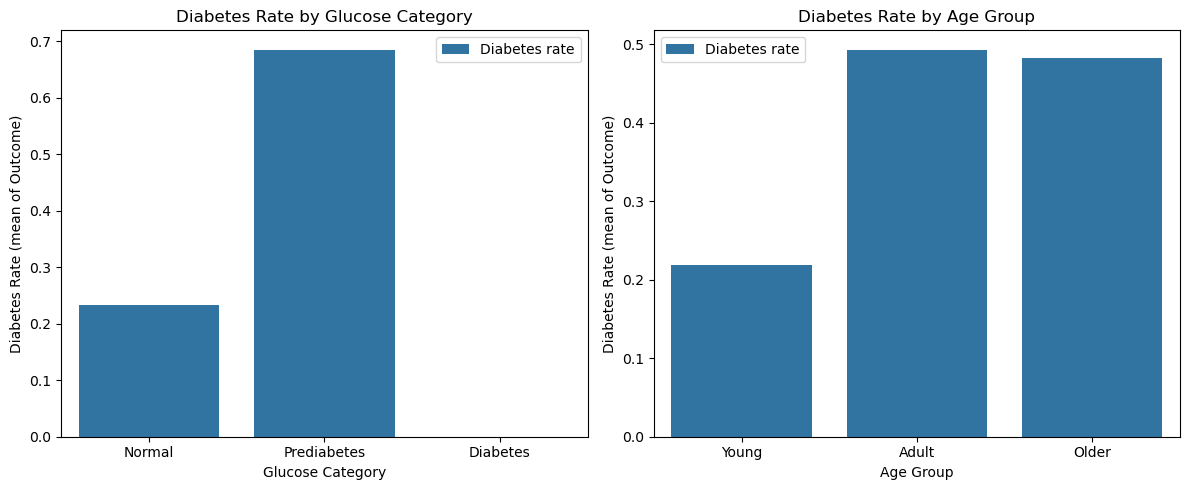

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=df_clean, x="Glucose_Category", y="Outcome", errorbar=None, ax=axes[0], label="Diabetes rate")
axes[0].set_title("Diabetes Rate by Glucose Category")
axes[0].set_xlabel("Glucose Category")
axes[0].set_ylabel("Diabetes Rate (mean of Outcome)")
axes[0].legend()

sns.barplot(data=df_clean, x="Age_Group", y="Outcome", errorbar=None, ax=axes[1], label="Diabetes rate")
axes[1].set_title("Diabetes Rate by Age Group")
axes[1].set_xlabel("Age Group")
axes[1].set_ylabel("Diabetes Rate (mean of Outcome)")
axes[1].legend()

plt.tight_layout()
plt.show()

<div dir="rtl">

### ملاحظة بعد الرسم

بالنسبة لتصنيف السكر (`Glucose_Category`)؛ توقعي لنسبة الإصابة في فئة ما قبل السكري (`Prediabetes`) كان 55 % بينما الفعلي طلع 69 % ، يعني النسبة الفعلية كانت أعلى من المتوقع. وفي فئة الطبيعي (`Normal`) كانت نسبة الإصابة حوالي 23 % ، وهالشي يدعم توقعي بان ارتفاع السكر يرتبط بزيادة خطر الاصابة

لكن في الفئات العمرية (`Age_Group`) توقعي لفئة الكبار (`Older`) كان 50 %  والفعلي طلع 48 % ، يعني كان توقعي قريب تقريبا وفئة الصغار (`Young`) كانت نسبة الإصابة فيها حوالي 22 % ، بينما البالغين (`Adult`) كانت 49 %. والملاحظة المهمة هنا أن فئتي البالغين والكبار تقريبا نفس النسبة (49 % و48 %)، يعني ارتفاع الخطر يظهر بعد سن 30 وما يرتفع زيادة بعد سن 50 في هذي البيانات (مع الأخذ بعين الاعتبار إن فئة الكبار صغيرة)

ومهم نلاحظ ان فئة السكري (`Diabetes`) فيها صفر صف لان أعلى قيمة للسكر في البيانات هي 199، وبرضو فئة الكبار (`Older`) تحتوي على 87 صف بس (يعني 11.6 %)، عشان كذا نتائجها تعتبر أقل ثبات من باقي الفئات

</div>

<div dir="rtl">

### توقع قبل الرسم

- أتوقع يبقى السكر (`Glucose`) أقوى متغير ارتباطا مع النتيجة (`Outcome`) بقيمة تقارب 0.50، وبعده مؤشر كتلة الجسم (`BMI`) بقيمة تقارب 0.30
- أتوقع تكون أضعف المتغيرات هي ضغط الدم (`BloodPressure`) والتاريخ العائلي (`DiabetesPedigreeFunction`) بقيم أقل من 0.20

</div>

In [27]:
corr_target = df_clean.corr(numeric_only=True)["Outcome"].drop("Outcome").sort_values(ascending=False)
print(corr_target)

Glucose                     0.494190
BMI                         0.309884
Age                         0.232734
Pregnancies                 0.213371
SkinThickness               0.211854
Insulin                     0.203889
DiabetesPedigreeFunction    0.178052
BloodPressure               0.162308
Name: Outcome, dtype: float64


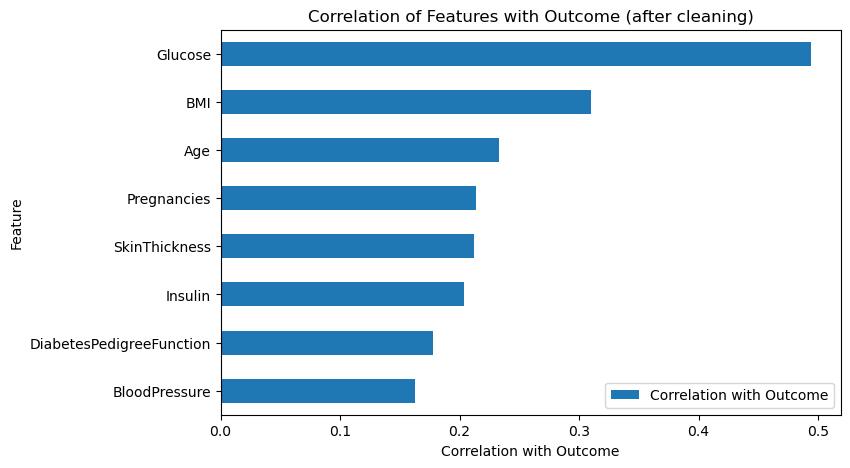

In [28]:
plt.figure(figsize=(8, 5))
corr_target.plot(kind="barh", label="Correlation with Outcome")
plt.title("Correlation of Features with Outcome (after cleaning)")
plt.xlabel("Correlation with Outcome")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.legend()
plt.show()

<div dir="rtl">

### ملاحظة بعد الرسم

توقعي كان صحيح بشكل كبير:

- السكر (`Glucose`) طلع أقوى متغير ارتباط مع النتيجة بقيمة 0.494 (توقعت حوالي 0.50)، وبعده مؤشر كتلة الجسم (`BMI`) بقيمة 0.310 (توقعت حوالي 0.30)
- أضعف المتغيرات كانت ضغط الدم (`BloodPressure`) بقيمة 0.162 والتاريخ العائلي (`DiabetesPedigreeFunction`) بقيمة 0.178 مثل ما توقعت

بمقارنة النتائج مع الرسم السابق قبل التنظيف، ارتفع ارتباط سمك الجلد (`SkinThickness`) من 0.07 إلى 0.212، والأنسولين (`Insulin`) من 0.13 إلى 0.204، وضغط الدم من 0.07 إلى 0.162. هالشي يثبت ان الأصفار كانت تخفي العلاقة الحقيقية

بناء على هالأرقام، قررت أبقي على سمك الجلد والأنسولين لأن ارتباطهم تجاوز 0.20 بعد التنظيف، وايضا أبقيت على ضغط الدم بعد تحسن ارتباطه وتقديمه لمعلومات مفيدة للنموذج

</div>

<div dir="rtl">

### جدول اختيار الميزات (Feature Selection)

| العمود | القرار | الدليل والسبب |
| :--- | :---: | :--- |
| **Glucose** | إبقاء | أعلى ارتباط مع Outcome بقيمة 0.494 ويعتبر أهم مؤشر للسكري |
| **BMI** | إبقاء | ثاني أعلى ارتباط بقيمة 0.310 وله أهمية طبية واضحة |
| **Age** | إبقاء | ارتباطه 0.233 ويعتبر عامل خطر معروف للإصابة بالسكري |
| **Pregnancies** | إبقاء | رغم ان ارتباطه مع Age قوي (0.54)، أبقيته لأن ارتباطه مع Outcome 0.213 ويضيف معلومة طبية مختلفة ومستقلة |
| **SkinThickness** | إبقاء | ارتفع ارتباطه من 0.07 إلى 0.212 بعد التنظيف، مما يثبت ان الأصفار كانت تخفي العلاقة الحقيقية |
| **Insulin** | إبقاء | ارتفع ارتباطه من 0.13 إلى 0.204 بعد التنظيف، وبناء عليه قررت الاحتفاظ به |
| **DiabetesPedigreeFunction** | إبقاء | ارتباطه 0.178 ويمثل التاريخ العائلي للإصابة بالسكري |
| **BloodPressure** | إبقاء | ارتفع ارتباطه من 0.07 إلى 0.162 بعد التنظيف وصار أكثر فائدة من السابق |
| **Glucose_Category و Age_Group** | حذف | مشتقة من Glucose و Age الموجودتين أصلاً، وفيها مشاكل تمثيل مثل فئة Diabetes الفاضية (0 صف) وفئة Older الصغيرة (87 صف) |
| **Outcome** | Target | المتغير المستهدف للتنبؤ بالإصابة بالسكري |

</div>

In [29]:
final_cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
              "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]

df_final = df_clean[final_cols]
df_final.to_csv("diabetes_model_ready.csv", index=False)

print(df_final.shape)
print(df_final.isnull().sum().sum())

(752, 9)
0


<div dir="rtl">

### النتائج والتوصيات

**1. ماذا اكتشفت؟**
- اكتشفت ان 376 صف من أصل 768 صف (يعني 49% من البيانات) فيها قيمة صفر واحدة على الأقل في الأعمدة الصحية المهمة، وهذا يدل على وجود قيم مفقودة مخزنة على شكل أصفار
- أقوى عامل مرتبط بالإصابة بالسكري كان السكر (`Glucose`) بقيمة ارتباط 0.494، وبعده مؤشر كتلة الجسم (`BMI`) بقيمة 0.310
- ارتفعت نسبة الإصابة بالسكري من حوالي 23% في فئة الطبيعي (`Normal`) إلى حوالي 69% في فئة ما قبل السكري (`Prediabetes`)، وايضا ارتفعت من 22% في فئة الصغار (`Young`) إلى حوالي 49% في فئة البالغين (`Adult`)

**2. التوصيات للعيادة**
- التركيز على الفحص المبكر للمرضى اللي مستوى السكر (`Glucose`) عندهم 140 فأكثر، لان نسبة الإصابة فيهم توصل إلى 69%، والسكر هو أقوى عامل مرتبط بالمرض (0.494)
- بدء الفحص الدوري مبكر من سن 30 بدل انتظار سن 50، لان نسبة الإصابة في فئة البالغين `Adult` (49%) وفئة الكبار `Older` (48%) طلعت متقاربة
- إعطاء اهتمام إضافي للمرضى أصحاب مؤشر كتلة الجسم (`BMI`) المرتفع، لانه ثاني أقوى عامل مرتبط بالإصابة (0.310)
- تحسين طريقة جمع البيانات ومنع تسجيل القيم المفقودة كأصفار، لان 49% من السجلات تأثرت بهذه المشكلة

**3. حدود التحليل**
- البيانات غير متوازنة من ناحية المتغير المستهدف (`Outcome`)، بحيث ان عدد المصابات 268 مقابل 500 غير مصابات (يعني نسبة الإصابة 34.9%)، وهذه نقطة لازم ينتبه لها أي نموذج تنبؤي ينبني بالمستقبل
- تم تعويض عدد كبير من قيم الأنسولين (`Insulin`) المفقودة، بحيث كان يحتوي على 374 قيمة صفر (حوالي 49% من البيانات)، وبالتالي ممكن تتأثر نتائجه بعملية التعويض
- فئة الكبار (`Older`) تحتوي على 87 صف بس (11.6% من البيانات)، مما يخلي نتائجها أقل استقرار من باقي الفئات
- الارتباط لا يعني السببية، وبالتالي ما نقدر نجزم ان أي عامل يسبب السكري بشكل مباشر اعتماد على هذا التحليل لوحده

</div>

تم حفظ الداتا الجاهزة في ملف `diabetes_model_ready.csv`: **752 صف و 9 أعمدة، بدون أي قيم ناقصة**.

## Task 2

<div dir="rtl">

### ملخص لطبيب العيادة

بعد تنظيف البيانات وتحليلها، وجدت أن أهم ثلاثة عوامل مرتبطة بالإصابة بالسكري هي السكر (`Glucose`) بقيمة ارتباط 0.494، بعده مؤشر كتلة الجسم (`BMI`) بقيمة 0.310، ثم العمر (`Age`) بقيمة 0.233، مثل ما يظهر في رسمة الارتباط في قسم اختيار الميزات. لذلك يبدو أن مستوى السكر ومؤشر كتلة الجسم والعمر هي أكثر العوامل ارتباطا بالإصابة في هذه البيانات

أكبر مشكلة في البيانات كانت وجود قيم مفقودة مخزنة على شكل أصفار غير منطقية طبيا. على سبيل المثال، احتوى عمود الأنسولين (`Insulin`) على 374 قيمة صفر وعمود سمك الجلد (`SkinThickness`) على 227 قيمة صفر. بالنسبة للسكر ومؤشر كتلة الجسم حذفت 16 صف فقط لان عدد الأصفار كان قليل، بينما عوضت القيم المفقودة في ضغط الدم وسمك الجلد والأنسولين باستخدام الوسيط (72 و29 و125.5) لان الوسيط أقل تأثرا بالقيم المتطرفة، ولان الأصفار في هذه المتغيرات غير ممكنة طبيا

أوصي العيادة باستخدام فحص السكر (`Glucose`) كأول خطوة في الفرز المبكر للمرضى، لان مستوى السكر كان أقوى عامل ارتباط بالسكري (0.494). وظهرت النتائج أن نسبة الإصابة ارتفعت من حوالي 23% في فئة الطبيعي (`Normal`) إلى حوالي 69% في فئة ما قبل السكري (`Prediabetes`)، مما يشير إلى أهمية متابعة المرضى الذين مستويات السكر لديهم مرتفعه

من المهم أيضا معرفة ما لا تستطيع البيانات إثباته. هذا التحليل يوضح وجود ارتباطات بين المتغيرات والسكري، لكنه لا يثبت أن هذه العوامل تسبب المرض بشكل مباشر. على سبيل المثال، لا يمكننا القول إن ارتفاع السكر يسبب السكري أو أن خفض مؤشر كتلة الجسم سيمنع الإصابة اعتمادا على هذه البيانات فقط. كذلك فإن هذه البيانات مأخوذة من مجموعة محددة من النساء، لذلك يجب الحذر عند تعميم النتائج على جميع السكان

</div>